# Levitated optomechanics: from optical forces to linear quadratic Gaussian (LQG) stabilisation
### An illustrated, executable tutorial with one numerical example throughout

**Goal.** Understand (1) why light can trap a particle, (2) how the particle moves in a noisy optical potential, (3) the difference between cooling a stable trap and stabilising an unstable one, and (4) how a Kalman filter and a linear quadratic regulator (LQR) form an LQG controller.

**Approach.** We start from Newton's law, explain a three-dimensional optical trap before using a generic one-dimensional mechanical coordinate and, finally, a two-dimensional double well, and generate figures from the central equations. No control-systems package is required: just NumPy, SciPy and Matplotlib.

**Source and scope.** Motivated by Mlynář *et al.* (and colleagues), *FPGA-based LQG controller and hardware-in-the-loop simulator implementation for nanomechanical systems* (2026), especially §§2–4 and Fig. 5 (the supplied portable document format (PDF) article). The paper uses a field-programmable gate array (FPGA) controller and a second FPGA as a hardware-in-the-loop (HIL) simulator. **Our examples are illustrative software simulations, not reproductions of its measured traces or parameter settings.** We use classical mechanics and classical stochastic control; we do not claim quantum ground-state cooling.

**Learning path:** Run all cells in order. Figures are produced automatically. Experiment with the clearly marked parameters and exercises near the end.

## Abbreviations, notation and units

The main abbreviations are collected here so that you can refer back to them while reading. **Abbreviations** name techniques or hardware; **mathematical symbols** such as $A$, $B$, $Q$, $R$, $q$ and $\Omega$ are variables rather than abbreviations and are introduced where used.

### Symbols at a glance

| Symbol | Meaning |
|:--|:--|
| $x$ | Physical **axial** coordinate; the laser propagates along $+x$. |
| $y,z$ | Physical **transverse** coordinates, perpendicular to the laser. |
| $q$, $v=\dot q$ | Generic one-dimensional mechanical displacement and velocity in the control examples. |
| $\mathbf s=[q,v]^T$ | Mechanical state vector (not the spatial coordinate $z$). |
| $k_{\perp}$ | Optical transverse spring stiffness in N/m. |
| $k_x,k_y,k_z$ | *Local mechanical trap stiffnesses* in N/m, evaluated at the equilibrium; not the optical wavenumber. |
| $x_{\mathrm{eq}}$ | Axial optical-trap equilibrium measured from the beam focus ($x=0$). |
| $k_0=2\pi/\lambda$ | Optical wavenumber in rad/m, distinct from $k_x,k_y,k_z$. |
| $n$, $\epsilon_r=n^2$ | Relative refractive index and relative permittivity of a nonmagnetic dielectric particle. |
| $\sigma_{\mathrm{scat}}$ | Rayleigh scattering cross-section in m$^2$. |
| $g_q,g_v$ | Feedback gains on the normalised displacement and velocity; **not** optical spring stiffness. |
| $U$, $V$ | Physical optical potential energy and dimensionless/normalised model potential, respectively. |
| $Q_{\mathrm{LQR}}$, $Q_d$ | LQR cost weight and discrete stochastic process-noise covariance; different quantities. |
| $\chi_k$ | Sampled detector measurement used by the Kalman filter. |

**Coordinate convention throughout:** the optical beam propagates along **$+x$**; $y$ and $z$ are transverse coordinates. For the subsequent single-mode control problems, **$q$ denotes a generic mechanical displacement**, $v=\dot q$ its velocity, and $\mathbf s=[q,v]^T$ its state. This avoids identifying a generic controlled mode with the beam axis. The paper's two-dimensional potential is written in $q_1,q_2$; these are mode coordinates, not necessarily the laboratory $x,y$ axes.

| Abbreviation | Full form | Meaning in this tutorial |
|:--|:--|:--|
| **LQR** | **Linear Quadratic Regulator** | Optimal *state-feedback design*: selects gains to minimise a quadratic cost on motion and control effort. |
| **LQG** | **Linear Quadratic Gaussian** | The combination of an LQR controller and a Kalman state estimator for a linear system with Gaussian noise. |
| **FPGA** | **Field-Programmable Gate Array** | Reconfigurable digital hardware used to run the estimator and feedback law with predictable timing. |
| **HIL** | **Hardware-in-the-Loop** | Testing a real hardware controller against a real-time *simulated* physical plant. |
| **PD** | **Proportional–Derivative** | Feedback based on position error and its rate of change (velocity-like action). |
| **PID** | **Proportional–Integral–Derivative** | PD feedback with an additional integral term to correct persistent errors. |
| **MPC** | **Model Predictive Control** | Repeatedly solves a finite-horizon optimisation problem; can explicitly include actuator constraints. |
| **PDF** | **Portable Document Format** | File format of the cited research paper. |
| **1D / 2D / 3D** | **One / two / three dimensions** | Number of spatial directions in a model or optical trap. |

**A mathematical name, not an abbreviation:** $H_\infty$ is read *H-infinity*. In this context, it refers to a robust-control approach based on bounding the worst-case disturbance-to-output gain.

### Unit symbols appearing in text, plots and code

| Symbol | Unit | Used for |
|:--|:--|:--|
| **m, nm, $\mu$m** | metre, nanometre ($10^{-9}$ m), micrometre ($10^{-6}$ m) | Particle sizes, wavelength and beam waist. |
| **s, ns, $\mu$s** | second, nanosecond ($10^{-9}$ s), microsecond ($10^{-6}$ s) | Sampling periods and feedback delays. |
| **Hz, kHz, MHz** | hertz, kilohertz ($10^3$ Hz), megahertz ($10^6$ Hz) | Oscillation frequencies and FPGA sampling frequency. |
| **W, mW** | watt, milliwatt ($10^{-3}$ W) | Laser power. |
| **N, fN** | newton, femtonewton ($10^{-15}$ N) | Force. |
| **V** | volt | Detector and actuation signals in the physical experiment. |
| **F** | farad | Electric capacitance; appears in the polarizability unit $\mathrm{F\,m^2}$. |
| **kg** | kilogram | Particle mass. |
| **arb.** | arbitrary units | A plot shows a relative or normalised quantity rather than a calibrated physical magnitude. |

In citations, *et al.* is Latin shorthand for “and others”; **Fig.** means **Figure** and **§** means **section**. These are editorial conventions rather than control-system terminology.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are, solve_discrete_are, expm
from scipy.signal import cont2discrete
from scipy.stats import norm
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True, 'grid.alpha': .25, 'font.size': 11})
rng = np.random.default_rng(12)
print('Ready: NumPy', np.__version__)

Ready: NumPy 2.4.6


## 1. How can light hold up a particle?

A laser exerts **two different forces** on a transparent dielectric particle:

- The **gradient force** pulls it towards regions of *higher light intensity* (for a particle with positive polarizability).
- The **scattering force** pushes it *along the direction in which the laser travels*; here that is **$+x$**.

A useful mental picture for a **large** transparent sphere is *refraction*: the sphere bends light rays, changing their momentum. Momentum conservation produces a reaction force on the sphere. If the sphere is off-centre in a beam, there is more light on the brighter side, so the sideways momentum transfers need not cancel. This explains the inward gradient force in the ray-optics regime.

For a **nanoparticle much smaller than the wavelength** (the Rayleigh regime), individual light rays are not a good approximation. Instead, the electric field of the laser induces a dipole:

$$
\mathbf p=\alpha\mathbf E,
$$

where $\alpha$ is its *polarizability*. For a small nonabsorbing sphere of radius $a$ in vacuum,

$$
\alpha=4\pi\epsilon_0a^3\frac{\epsilon_r-1}{\epsilon_r+2}.
$$

For a nonmagnetic dielectric sphere, $\epsilon_r=n^2$, where $n$ denotes the relative refractive index (the same $n$ used in the infographic). The electric field makes the positive and negative charges shift slightly in opposite directions. **A larger field induces a larger dipole and lowers the interaction energy more.** For real, positive $\alpha$, the time-averaged energy in a laser field with *peak* electric-field amplitude $E_0$ is

$$
U(\mathbf r)=-\frac14\alpha |E_0(\mathbf r)|^2
=-\frac{\alpha}{2\epsilon_0c}I(\mathbf r).
$$

The **minus sign** is the important part: bright regions have *lower potential energy*. Taking the spatial derivative gives the gradient force:

$$
\boxed{\mathbf F_{\mathrm{grad}}=-\nabla U
=\frac{\alpha}{2\epsilon_0c}\nabla I.}
$$

This force vanishes in a perfectly uniform beam and, transversely, at the exact centre of a symmetric beam. A particle displaced to either side is pulled back towards the intensity maximum.

### Why does the scattering force push forwards?

A photon carries momentum $p_\gamma=h/\lambda$. Even a **transparent** sphere redirects (scatters) photons. The incident beam loses some of its *forward* momentum, which must be transferred to the sphere. In the Rayleigh regime, the forward scattering force of a nonabsorbing sphere is approximately

$$
\boxed{\mathbf F_{\mathrm{scat}}=\frac{I\,\sigma_{\mathrm{scat}}}{c}\,\hat{\mathbf x}},\qquad
\sigma_{\mathrm{scat}}=\frac{k_0^4\alpha^2}{6\pi\epsilon_0^2},\quad
k_0=\frac{2\pi}{\lambda}.
$$

The two forces are **not opposite versions of the same force**: the gradient force follows the *spatial change* in intensity; the scattering force follows the *propagation direction*. At the transverse beam centre, the gradient force is zero while the scattering force is generally nonzero.

**Particle-size intuition:** in this approximation $\alpha\propto a^3$, so $F_{\mathrm{grad}}\propto a^3$, whereas $\sigma_{\mathrm{scat}}\propto a^6$, so $F_{\mathrm{scat}}\propto a^6$. Shrinking the particle reduces scattering more rapidly than the gradient force, with the illumination held fixed.

**Coordinate convention for the optical trap:** the laser propagates to the right along $+x$; the bright core is centred at $y=z=0$. The gradient force restores displacements in $y$ and $z$, while its **axial component** can point toward $-x$ downstream of the focus. Scattering is always approximately toward $+x$. A stable axial equilibrium, when it exists, is generally slightly **downstream** of the focus. The optical intensity alone does not guarantee that the axial gradient is strong enough to trap the particle. The single-mode controller introduced later uses $q$, not the optical $x$ coordinate.


### A visual overview: the three-dimensional optical trap

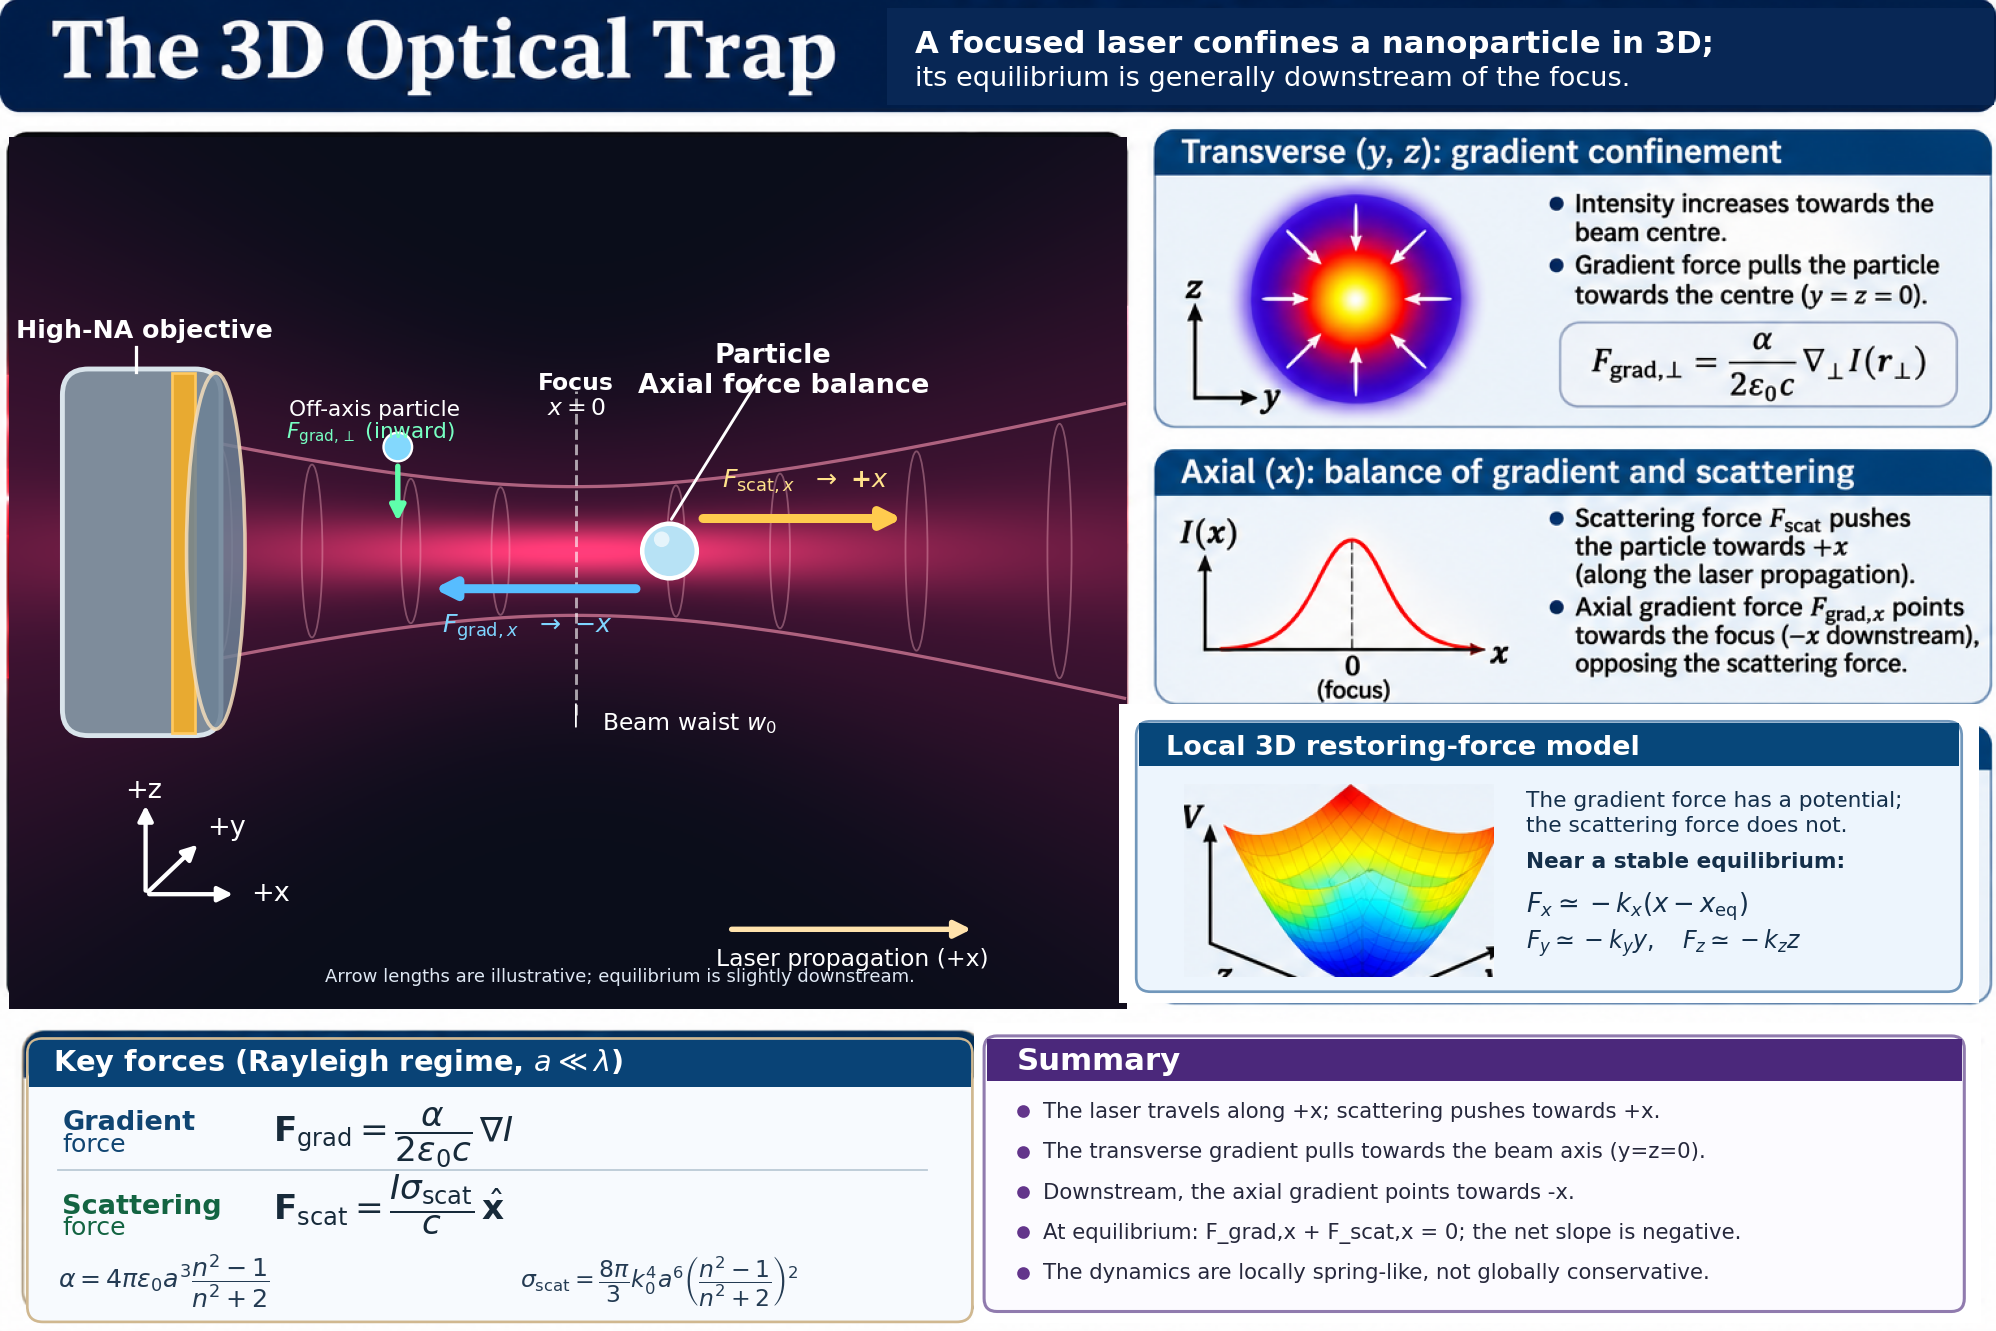

*Reworked from the supplied infographic to correct the force arrows and notation.* In this tutorial, the laser propagates along **$+x$**. The bright beam axis is **$y=z=0$**, and the focus is at **$x=0$**. The depicted particle is slightly **downstream**, at $x=x_{\mathrm{eq}}>0$:

- **Scattering:** $F_{\mathrm{scat},x}>0$, always pushing in the $+x$ direction in this model.
- **Axial gradient:** $F_{\mathrm{grad},x}<0$ for $x>0$ near the focus, pulling back towards the intensity maximum. The arrows oppose one another at equilibrium.
- **Transverse gradient:** a particle displaced from $y=z=0$ feels an inward force. At the *on-axis* equilibrium itself, these transverse force components vanish.

The Rayleigh approximation uses the particle radius $a$, its relative refractive index $n$, and the *optical wavenumber* $k_0=2\pi/\lambda$:

$$
\alpha=4\pi\epsilon_0a^3\frac{n^2-1}{n^2+2},\qquad
\sigma_{\mathrm{scat}}=\frac{8\pi}{3}k_0^4a^6
\left(\frac{n^2-1}{n^2+2}\right)^2.
$$

For nonmagnetic silica, $\epsilon_r=n^2$, so this $\alpha$ is **identical** to the permittivity-based expression above. The full gradient-force law is $\mathbf F_{\mathrm{grad}}=\alpha\nabla I/(2\epsilon_0c)$, with a **positive** sign for positive $\alpha$; the vector direction comes from the intensity gradient.

**Local, not global:** the scattering force is nonconservative. The bowl illustrates *approximately harmonic restoring behaviour near the stable equilibrium*, not an exact global potential for the combined gradient and scattering forces. With $\delta x=x-x_{\mathrm{eq}}$, a locally diagonalised model is

$$
F_x\simeq-k_x\delta x,\qquad F_y\simeq-k_y y,\qquad F_z\simeq-k_z z,
$$

where $k_x,k_y,k_z>0$ are **mechanical stiffnesses**, distinct from $k_0$. The subsequent numerical code evaluates the axial balance and checks the restoring slope. The arrows in the diagram indicate **directions**, not calibrated force magnitudes.


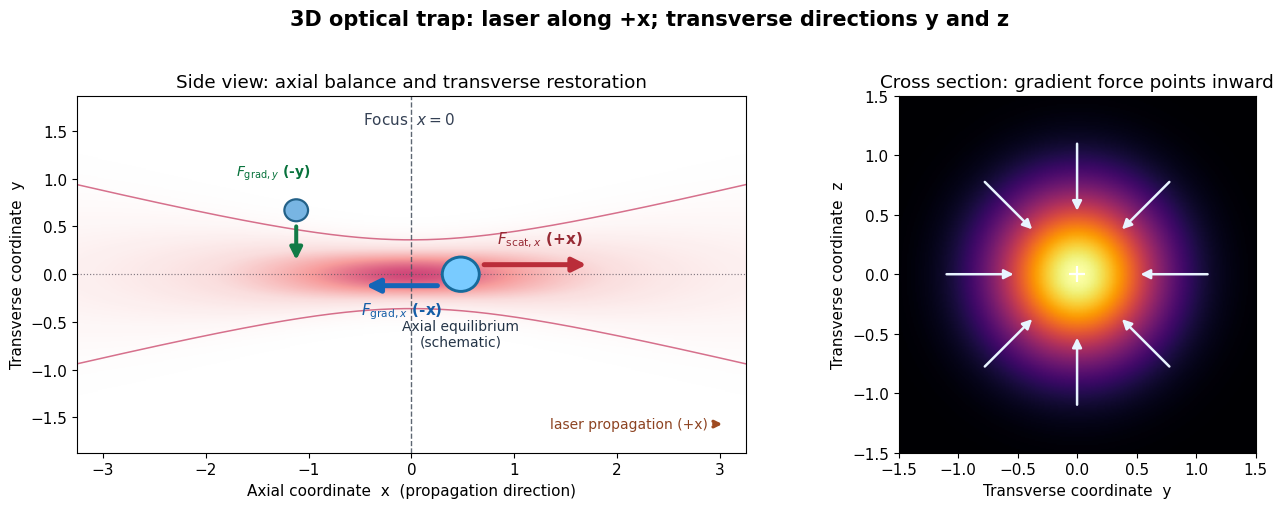

In [2]:
# Geometrically consistent 3D-trap schematic (2D side view plus y-z section).
# Beam propagation is +x; y,z are transverse. Arrows indicate directions,
# not calibrated magnitudes. A displaced test particle illustrates F_grad,y.
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap

fig = plt.figure(figsize=(13, 5.1), facecolor='white')
gs = fig.add_gridspec(1, 2, width_ratios=[1.65, 1], wspace=0.24)
ax = fig.add_subplot(gs[0,0])
ax2 = fig.add_subplot(gs[0,1])
xx_beam = np.linspace(-3.25, 3.25, 520)
yy_beam = np.linspace(-1.9, 1.9, 330)
XX_beam, YY_beam = np.meshgrid(xx_beam, yy_beam)
# Qualitative Gaussian beam envelope and intensity, waist at x=0.
w_env = 0.36 * np.sqrt(1 + (XX_beam / 1.35)**2)
I_display = np.exp(-2 * (YY_beam / w_env)**2) / (w_env / 0.36)**2
warm_cmap = LinearSegmentedColormap.from_list('beam_pink', ['#FFFFFF','#FAD9D9','#F68F8F','#CC3269'])
ax.imshow(I_display, extent=[xx_beam.min(),xx_beam.max(), yy_beam.min(),yy_beam.max()],
          origin='lower', cmap=warm_cmap, alpha=0.89, aspect='auto',zorder=0)
ax.plot(xx_beam,0.36*np.sqrt(1+(xx_beam/1.35)**2),c='#CC4D70',lw=1.1,alpha=.8)
ax.plot(xx_beam,-0.36*np.sqrt(1+(xx_beam/1.35)**2),c='#CC4D70',lw=1.1,alpha=.8)
ax.axhline(0,color='#5C5460',lw=0.85,ls=':',alpha=.75)
ax.axvline(0,color='#4B5563',lw=1,ls='--',alpha=.9)
ax.text(-.02,1.71,'Focus  $x=0$',ha='center',va='top',size=11,color='#344054')
# Particle is DOWNSTREAM (right) of the focus.
x_eq_sch, y_eq_sch = 0.48, 0
ax.add_patch(Circle((x_eq_sch,y_eq_sch),.18,fc='#79CBFF',ec='#176B9C',lw=2.1,zorder=9))
# The two axial force arrows are drawn on different horizontal levels for clarity.
ax.annotate('',xy=(x_eq_sch+1.25,.10),xytext=(x_eq_sch+.20,.10),
            arrowprops=dict(arrowstyle='-|>',color='#BA2D39',lw=3.6,mutation_scale=20),zorder=11)
ax.text(x_eq_sch+.77,.32,r'$F_{\mathrm{scat},x}$ (+x)',color='#972B35',weight='bold',ha='center',size=11)
ax.annotate('',xy=(x_eq_sch-.95,-.12),xytext=(x_eq_sch-.20,-.12),
            arrowprops=dict(arrowstyle='-|>',color='#1466B8',lw=3.6,mutation_scale=20),zorder=11)
ax.text(x_eq_sch-.57,-.42,r'$F_{\mathrm{grad},x}$ (-x)',color='#155EA7',weight='bold',ha='center',size=11)
ax.text(x_eq_sch,-.75,'Axial equilibrium\n(schematic)',ha='center',size=10,color='#243447')
# Separate particle displaced in +y direction, with inward restoring force.
x_test, y_test = -1.12, .67
ax.add_patch(Circle((x_test,y_test),.115,fc='#78B5E3',ec='#236188',lw=1.6,zorder=9))
ax.annotate('',xy=(x_test,.12),xytext=(x_test,y_test-.14),
            arrowprops=dict(arrowstyle='-|>',color='#117B46',lw=2.9,mutation_scale=18),zorder=10)
ax.text(x_test-0.22,1.03,r'$F_{\mathrm{grad},y}$ (-y)',ha='center',size=10,color='#08723C',weight='bold')
ax.annotate('laser propagation (+x)',xy=(3.05,-1.57),xytext=(1.35,-1.57),
            arrowprops=dict(arrowstyle='->',lw=2.4,color='#9F4B21'),color='#8D4321',va='center',size=10)
ax.set(xlim=(-3.25,3.25),ylim=(-1.87,1.87),xlabel='Axial coordinate  x  (propagation direction)',
       ylabel='Transverse coordinate  y',title='Side view: axial balance and transverse restoration')
ax.grid(False)
# y-z transverse cross section: intensity maximum at centre, restoring inward arrows.
yz = np.linspace(-1.5,1.5,260); YY,ZZ=np.meshgrid(yz,yz)
ax2.imshow(np.exp(-2*(YY**2+ZZ**2)),extent=[-1.5,1.5,-1.5,1.5],origin='lower',
           cmap='inferno',aspect='equal')
for ang in np.linspace(0,2*np.pi,8,endpoint=False):
    yo,zo = 1.12*np.cos(ang),1.12*np.sin(ang)
    ax2.annotate('',xy=(.51*np.cos(ang),.51*np.sin(ang)),xytext=(yo,zo),
                 arrowprops=dict(arrowstyle='-|>',color='#E8F4FF',lw=1.8,mutation_scale=14))
ax2.plot(0,0,'w+',ms=11,mew=1.6)
ax2.set(xlabel='Transverse coordinate  y',ylabel='Transverse coordinate  z',
        title='Cross section: gradient force points inward')
ax2.grid(False)
fig.suptitle('3D optical trap: laser along +x; transverse directions y and z',weight='bold',fontsize=15,y=1.01)
fig.subplots_adjust(left=.06,bottom=.14,right=.985,top=.84,wspace=.28);plt.show()


### A numerical example with a silica nanoparticle

To see the different **directions and shapes** of the forces, consider a $100\,\mathrm{nm}$-diameter silica sphere ($n\approx1.45$) in a $1064\,\mathrm{nm}$ laser beam of power $P=10\,\mathrm{mW}$ and waist $w_0=0.8\,\mu\mathrm m$.

At the focus ($x=0$), for transverse displacement $y$ with $z=0$, use the Gaussian profile

$$
I(0,y,0)=I_0 e^{-2y^2/w_0^2},\qquad I_0=\frac{2P}{\pi w_0^2}.
$$

Its transverse gradient and forward scattering forces are

$$
F_{\mathrm{grad},y}=-\frac{2\alpha y}{\epsilon_0c w_0^2}I(0,y,0),\qquad
F_{\mathrm{scat},x}=\frac{\sigma_{\mathrm{scat}}}{c}I(0,y,0)>0.
$$

The gradient component $F_{\mathrm{grad},y}$ changes *sign* across the beam centre (restoring), but $F_{\mathrm{scat},x}$ points towards **$+x$** on both sides. These expressions use the Rayleigh and paraxial-Gaussian approximations; they do not alone guarantee axial trapping.


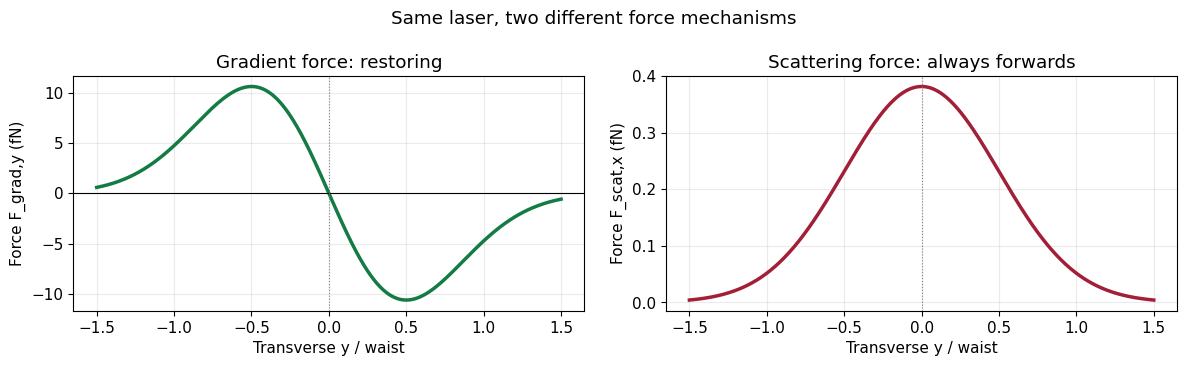

Polarizability: 3.74e-33 F m²
Scattering cross-section: 1.15e-17 m²
Transverse spring constant near centre: 4.38e-08 N/m
Approximate transverse trap frequency: 31.0 kHz
At y=z=0: transverse gradient force = 0; scattering pushes along +x.


In [3]:
# Physical-parameter example (independent of the later dimensionless LQG simulations)
eps0 = 8.8541878128e-12          # vacuum permittivity [F/m]
c0 = 299792458.0                 # speed of light [m/s]
lam = 1064e-9                    # wavelength [m]
a = 50e-9                        # sphere radius [m]
n_silica = 1.45                  # refractive index relative to vacuum
P_laser = 10e-3                  # laser power [W]
w_beam = 0.8e-6                  # Gaussian waist [m]
alpha = 4*np.pi*eps0*a**3*(n_silica**2-1)/(n_silica**2+2)
k0 = 2*np.pi/lam
sigma_scat = k0**4*alpha**2/(6*np.pi*eps0**2)
I0 = 2*P_laser/(np.pi*w_beam**2)
y_m = np.linspace(-1.5*w_beam, 1.5*w_beam, 601)
Iy = I0*np.exp(-2*(y_m/w_beam)**2)
Fy = -(2*alpha*y_m/(eps0*c0*w_beam**2))*Iy
Fx_scat = (sigma_scat/c0)*Iy

fig, axes = plt.subplots(1,2,figsize=(12,3.7))
axes[0].plot(y_m/w_beam, Fy*1e15,color='#137b43',lw=2.5)
axes[0].axhline(0,color='k',lw=.8)
axes[0].axvline(0,color='gray',lw=.8,ls=':')
axes[0].set(title='Gradient force: restoring',xlabel='Transverse y / waist',
            ylabel='Force F_grad,y (fN)')
axes[1].plot(y_m/w_beam, Fx_scat*1e15,color='#a21f38',lw=2.5)
axes[1].axvline(0,color='gray',lw=.8,ls=':')
axes[1].set(title='Scattering force: always forwards',xlabel='Transverse y / waist',
            ylabel='Force F_scat,x (fN)')
fig.suptitle('Same laser, two different force mechanisms')
fig.tight_layout(); plt.show()

U0 = alpha*I0/(2*eps0*c0)
k_perp = 4*U0/w_beam**2  # transverse stiffness k_y at focus
rho_silica = 2200.0  # kg/m^3, representative silica density
mass = (4/3)*np.pi*a**3*rho_silica
f_trap = np.sqrt(k_perp/mass)/(2*np.pi)
print(f'Polarizability: {alpha:.2e} F m²')
print(f'Scattering cross-section: {sigma_scat:.2e} m²')
print(f'Transverse spring constant near centre: {k_perp:.2e} N/m')
print(f'Approximate transverse trap frequency: {f_trap/1e3:.1f} kHz')
print('At y=z=0: transverse gradient force = 0; scattering pushes along +x.')

### How does the focused beam trap in all three dimensions?

The beam propagates along **$+x$** and is narrowest at the focus $x=0$. In the paraxial Gaussian approximation,

$$
\begin{aligned}
w(x)&=w_0\sqrt{1+(x/x_R)^2}, & x_R&=\frac{\pi w_0^2}{\lambda},\\
I(x,y,z)&=\frac{I_0}{1+(x/x_R)^2}
\exp\!\left[-\frac{2(y^2+z^2)}{w(x)^2}\right].
\end{aligned}
$$

Here $x_R$ is the **Rayleigh range** (not the particle radius). The **gradient force** follows $\nabla I$ in all three directions, while the **scattering force** points along $+x$:

$$
\mathbf F_{\mathrm{grad}}=\frac{\alpha}{2\epsilon_0c}\nabla I,
\qquad
\mathbf F_{\mathrm{scat}}=\frac{\sigma_{\mathrm{scat}} I}{c}\hat{\mathbf x}.
$$

Along the beam axis $y=z=0$, the **axial force** is

$$
F_x(x)=\underbrace{\frac{\alpha}{2\epsilon_0c}\frac{dI(x,0,0)}{dx}}_{F_{\mathrm{grad},x}}
+\underbrace{\frac{\sigma_{\mathrm{scat}}I(x,0,0)}{c}}_{F_{\mathrm{scat},x}}.
$$

At the focus, $dI/dx=0$, so scattering pushes towards $+x$. **Downstream ($x>0$)**, the axial gradient force points towards $-x$. A stable equilibrium $x_{\mathrm{eq}}>0$ can exist if these balance **and** $dF_x/dx<0$ there. The next graph calculates the force balance for our silica sphere.

A subtlety: scattering is nonconservative. The *gradient* part has an optical potential $U=-\alpha I/(2\epsilon_0c)$, but the **total 3D optical force is not generally the gradient of a single scalar potential**. A local harmonic approximation is nevertheless useful near a stable equilibrium.

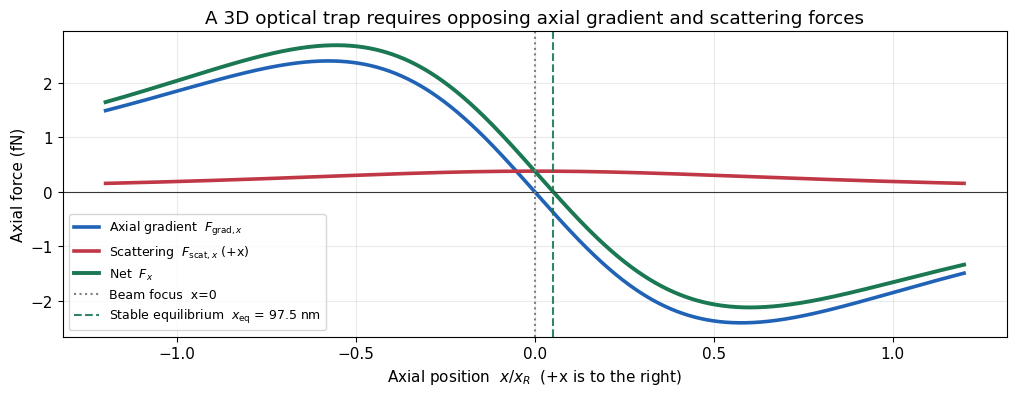

Rayleigh range x_R = 1.890 micrometres
Stable axial equilibrium x_eq = 97.5 nm downstream of focus
Net axial-force slope at equilibrium = -3.881e-09 N/m (negative is restoring)
Local stiffness k_x = 3.881e-09 N/m, k_y = k_z = 4.354e-08 N/m
The optical wavenumber k0 (rad/m) is not a mechanical stiffness k_x, k_y or k_z.


In [4]:
# Axial force balance for the SAME physical silica sphere as above.
# The laser travels along +x, with focus at x=0.
from scipy.optimize import brentq
x_R = np.pi * w_beam**2 / lam
x_ax = np.linspace(-1.2*x_R, 1.2*x_R, 2001)
I_ax = I0 / (1 + (x_ax/x_R)**2)
dI_dx = -2*I0*x_ax/x_R**2 / (1+(x_ax/x_R)**2)**2
F_grad_x = alpha/(2*eps0*c0) * dI_dx
F_scat_x = sigma_scat/c0 * I_ax
F_total_x = F_grad_x + F_scat_x

def axial_net_force(x_axial):
    I = I0/(1+(x_axial/x_R)**2)
    dI = -2*I0*x_axial/x_R**2/(1+(x_axial/x_R)**2)**2
    return alpha*dI/(2*eps0*c0)+sigma_scat*I/c0

cross = np.where((F_total_x[:-1]>0)&(F_total_x[1:]<0))[0]
if len(cross)==0:
    raise RuntimeError('No stable axial zero found: a 3D trap is not guaranteed by this approximation.')
i = cross[0]
x_eq = brentq(axial_net_force,x_ax[i],x_ax[i+1],xtol=1e-17)
dx_test = 1e-10
local_slope = (axial_net_force(x_eq+dx_test)-axial_net_force(x_eq-dx_test))/(2*dx_test)

fig,ax = plt.subplots(figsize=(10.3,4.1))
ax.plot(x_ax/x_R,F_grad_x*1e15,color='#2063B6',lw=2.6,label=r'Axial gradient  $F_{\mathrm{grad},x}$')
ax.plot(x_ax/x_R,F_scat_x*1e15,color='#C03845',lw=2.6,label=r'Scattering  $F_{\mathrm{scat},x}$ (+x)')
ax.plot(x_ax/x_R,F_total_x*1e15,color='#1A7852',lw=2.8,label=r'Net  $F_x$')
ax.axhline(0,color='#373737',lw=.8)
ax.axvline(0,color='gray',ls=':',label='Beam focus  x=0')
ax.axvline(x_eq/x_R,color='#1A7852',ls='--',alpha=.9,
           label=rf'Stable equilibrium  $x_{{\mathrm{{eq}}}}$ = {x_eq*1e9:.1f} nm')
ax.set(xlabel=r'Axial position  $x/x_R$  (+x is to the right)',ylabel='Axial force (fN)',
       title='A 3D optical trap requires opposing axial gradient and scattering forces')
ax.legend(fontsize=9,loc='lower left'); fig.tight_layout();plt.show()
print(f'Rayleigh range x_R = {x_R*1e6:.3f} micrometres')
print(f'Stable axial equilibrium x_eq = {x_eq*1e9:.1f} nm downstream of focus')
print(f'Net axial-force slope at equilibrium = {local_slope:.3e} N/m (negative is restoring)')
# Local spring constants about the actual 3D trapping equilibrium (not the beam focus).
k_x_eq = -local_slope  # N/m, axial restoring spring constant from net force
w_eq = w_beam*np.sqrt(1+(x_eq/x_R)**2)
I_eq = I0/(1+(x_eq/x_R)**2)
k_y_eq = 2*alpha*I_eq/(eps0*c0*w_eq**2)  # N/m; same for z by cylindrical symmetry
print(f'Local stiffness k_x = {k_x_eq:.3e} N/m, k_y = k_z = {k_y_eq:.3e} N/m')
print('The optical wavenumber k0 (rad/m) is not a mechanical stiffness k_x, k_y or k_z.')


**Connection to the next section:** near the bright centre, the gradient force is almost linear in displacement, $F_{\mathrm{grad},y}\simeq-k_y y$. That is exactly the **spring** in the harmonic-oscillator model used for the later Kalman filter and LQR. The scattering force primarily shifts the equilibrium along the direction of propagation; it is **not** the spring-like force in these transverse plots.

From Section 2 onwards, the **one-dimensional coordinate is $q$**: it stands for any chosen mechanical mode (e.g. a transverse displacement $y$), not necessarily the axial coordinate $x$. We later use dimensionless units to make the LQG simulations simple.

The stiffnesses $k_x,k_y,k_z$ in the infographic have units N/m and are positive at a stable equilibrium; the **dimensionless control gains** $g_q,g_v$ introduced later are different parameters.


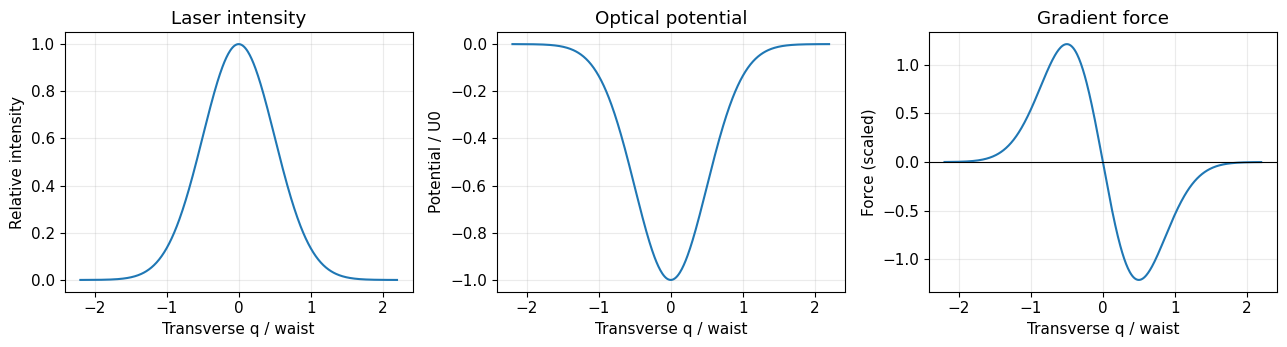

In [5]:
q_grid = np.linspace(-2.2, 2.2, 500)   # generic transverse displacement q / beam waist
I_rel = np.exp(-2*q_grid**2)
U_rel = -I_rel
F_rel = -4*q_grid*np.exp(-2*q_grid**2)  # -dU_rel/dq
fig, ax = plt.subplots(1, 3, figsize=(13,3.6))
ax[0].plot(q_grid,I_rel); ax[0].set(title='Laser intensity',xlabel='Transverse q / waist',ylabel='Relative intensity')
ax[1].plot(q_grid,U_rel); ax[1].set(title='Optical potential',xlabel='Transverse q / waist',ylabel='Potential / U0')
ax[2].plot(q_grid,F_rel); ax[2].axhline(0,color='k',lw=.8)
ax[2].set(title='Gradient force',xlabel='Transverse q / waist',ylabel='Force (scaled)')
fig.tight_layout();plt.show()


**Read the graphs:** the particle is attracted toward the intensity maximum at $q=0$. Close to that minimum, the force is approximately proportional to displacement: a spring. This is **one transverse cut** of the optical field; the axial force-balance plot in Section 1 explains the third direction.

## 2. The optical trap is approximately a harmonic oscillator

Taylor-expand the optical gradient potential around the centre of a transverse slice, $q=0$:

$$
U(q)\simeq-U_0+\frac12k_{\perp}q^2,\quad
k_{\perp}=\frac{4U_0}{w_0^2},\quad
\Omega=\sqrt{k_{\perp}/m}.
$$

Newton's law, including gas damping, external feedback and a fluctuating force, is

$$
m\ddot q+m\Gamma\dot q+m\Omega^2q=u_{\mathrm{phys}}(t)+F_{\mathrm{noise}}(t).
$$

The three important effects are **restoring stiffness** $m\Omega^2$, **damping** $m\Gamma$, and **random excitation**. The laser supplies restoring force in a stable trap; feedback is optional for passive confinement. Below, the **normalised control input** is written $u$ (with acceleration units absorbed into the normalisation).


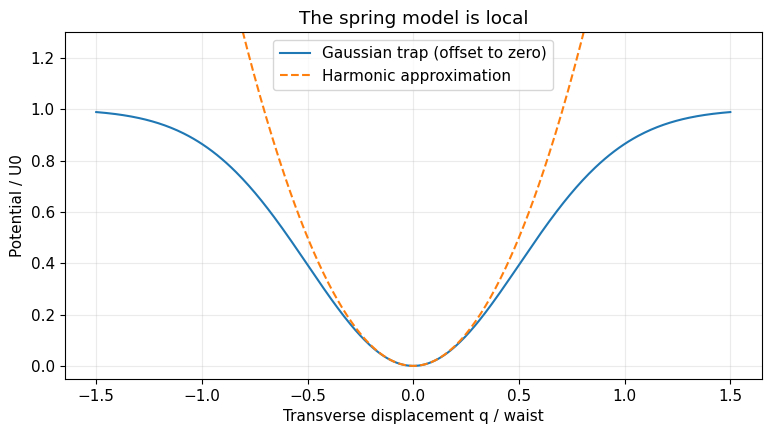

In [6]:
q_grid=np.linspace(-1.5,1.5,400)
U_exact=-np.exp(-2*q_grid**2)+1
U_quad=2*q_grid**2
plt.plot(q_grid,U_exact,label='Gaussian trap (offset to zero)')
plt.plot(q_grid,U_quad,'--',label='Harmonic approximation')
plt.ylim(-.05,1.3);plt.xlabel('Transverse displacement q / waist');plt.ylabel('Potential / U0')
plt.title('The spring model is local');plt.legend();plt.show()


## 3. Stable versus unstable equilibrium

A stable equilibrium sits at the **bottom** of an effective potential. A particle displaced slightly feels a restoring force. An unstable equilibrium sits at the **top**: a small displacement grows. Here $q$ is a generic mechanical mode, distinct from the optical propagation coordinate $x$:

$$
\text{Stable: }\ddot q=-\Omega^2q-\Gamma\dot q,\qquad
\text{Unstable: }\ddot q=+\Omega^2q-\Gamma\dot q.
$$

In the paper's saddle-potential demonstration, one mechanical mode is locally unstable. This is why feedback is **necessary for confinement**, not merely useful for cooling.


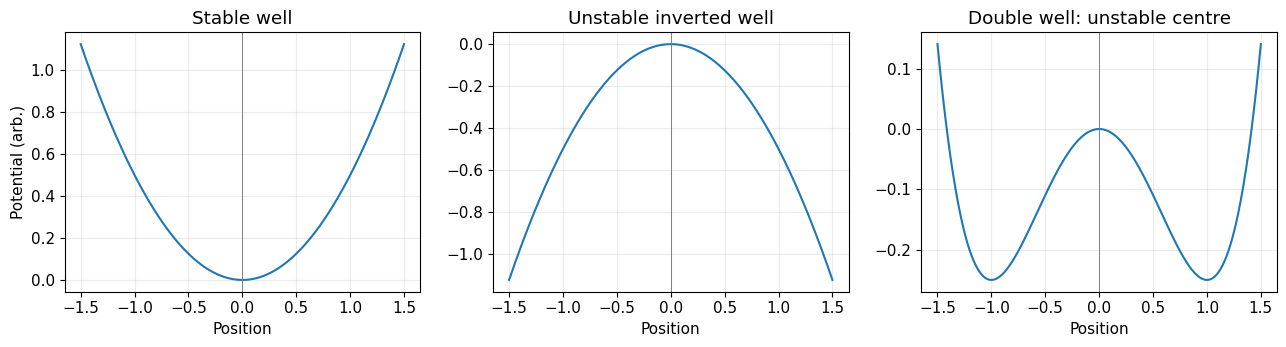

In [7]:
xx=np.linspace(-1.5,1.5,500)
fig,axs=plt.subplots(1,3,figsize=(13,3.6))
axs[0].plot(xx,.5*xx**2);axs[0].set(title='Stable well',ylabel='Potential (arb.)')
axs[1].plot(xx,-.5*xx**2);axs[1].set(title='Unstable inverted well')
axs[2].plot(xx,.25*xx**4-.5*xx**2);axs[2].set(title='Double well: unstable centre')
for a in axs:a.set(xlabel='Position');a.axvline(0,color='gray',lw=.7)
fig.tight_layout();plt.show()

## 4. One numerical particle, two kinds of trap

We now use **dimensionless units** so the plots are readable and the feedback equations are transparent. Time is measured in units of $1/\Omega_0$, and $q$ in an arbitrary reference displacement. Let $\Omega_0=1$ and damping $\Gamma=0.12$. This is *not* a fit to the paper's apparatus.

Write $v=\dot q$ and the **mechanical state vector** as $\mathbf s=[q,v]^T$. Let $\eta=+1$ denote stable stiffness and $\eta=-1$ inverted stiffness (we use $\eta$ rather than $s$ to avoid confusion with the state $\mathbf s$):

$$
\frac{d}{dt}\begin{bmatrix}q\\v\end{bmatrix}=
\underbrace{\begin{bmatrix}0&1\\-\eta\Omega_0^2&-\Gamma\end{bmatrix}}_A
\begin{bmatrix}q\\v\end{bmatrix}+
\underbrace{\begin{bmatrix}0\\1\end{bmatrix}}_B u.
$$

Here $u$ is the **normalised feedback force per unit mass**. First observe the unforced deterministic responses from the same initial displacement.


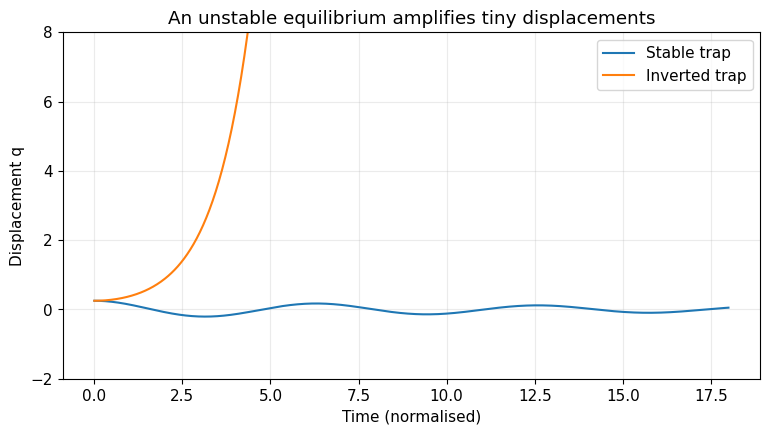

In [8]:
omega=1.0; gamma=.12
B=np.array([[0.],[1.]])
def plant(eta):
    return np.array([[0.,1.],[-eta*omega**2,-gamma]])
t=np.linspace(0,18,800)
state0=np.array([.25,0.])
plt.plot(t,[(expm(plant(1)*tt)@state0)[0] for tt in t],label='Stable trap')
plt.plot(t,[(expm(plant(-1)*tt)@state0)[0] for tt in t],label='Inverted trap')
plt.ylim(-2,8);plt.xlabel('Time (normalised)');plt.ylabel('Displacement q')
plt.title('An unstable equilibrium amplifies tiny displacements');plt.legend();plt.show()


## 5. What does feedback actually change?

Suppose we apply normalised acceleration feedback

$$
u=-g_q\,q-g_v\,v.
$$

For the inverted trap,

$$
\ddot q+(\Gamma+g_v)\dot q+(g_q-\Omega_0^2)q=0.
$$

Thus the controller must provide **positive effective stiffness** $g_q>\Omega_0^2$ (and positive total damping). In a stable trap, the main role of velocity feedback is often to increase damping, reducing motion caused by random disturbances. This is the difference between **stabilisation** and **cooling**.


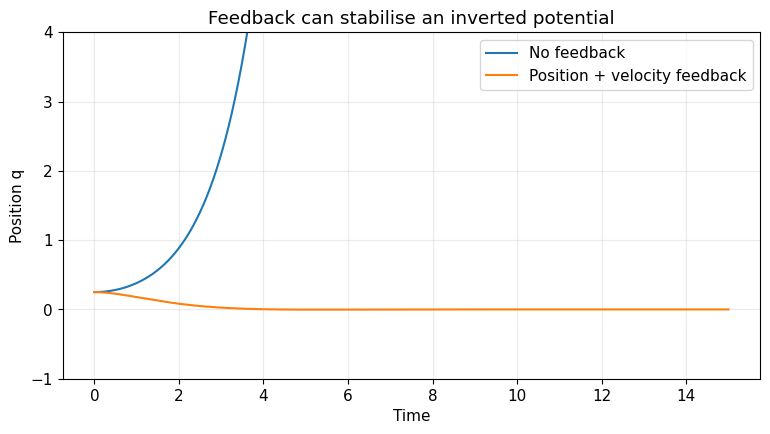

Open-loop poles: [ 0.942 -1.062]
Closed-loop poles: [-0.81+0.586j -0.81-0.586j]


In [9]:
from scipy.integrate import solve_ivp
K_example=np.array([2.0,1.5])
Aunstable=plant(-1)
Acl=Aunstable-B@K_example[None,:]
sol0=solve_ivp(lambda t,z:Aunstable@z,[0,15],state0,t_eval=np.linspace(0,15,600))
sol1=solve_ivp(lambda t,z:Acl@z,[0,15],state0,t_eval=np.linspace(0,15,600))
plt.plot(sol0.t,sol0.y[0],label='No feedback')
plt.plot(sol1.t,sol1.y[0],label='Position + velocity feedback')
plt.ylim(-1,4);plt.xlabel('Time');plt.ylabel('Position q');plt.title('Feedback can stabilise an inverted potential');plt.legend();plt.show()
print('Open-loop poles:',np.linalg.eigvals(Aunstable).round(3))
print('Closed-loop poles:',np.linalg.eigvals(Acl).round(3))

## 6. From feedback to optimal control: linear quadratic regulation (LQR)

Rather than guessing $g_q$ and $g_v$, choose them to minimise

$$
J=\int_0^\infty(\mathbf s^TQ_{\mathrm{LQR}}\mathbf s+r u^2)\,dt,
\quad \mathbf s=[q,v]^T.
$$

The matrix $Q_{\mathrm{LQR}}$ penalises displacement and velocity; $r>0$ penalises normalised control effort. For a *stable* harmonic trap, a physical energy-motivated choice is $Q_{\mathrm{LQR}}\propto\operatorname{diag}(\Omega_0^2,1)$. For the *inverted* trap, this is a positive surrogate state penalty, **not** the physical potential energy (which has negative curvature).

The optimal gain is $K=r^{-1}B^TP$, where $P$ solves the continuous algebraic Riccati equation

$$
A^TP+PA-PBr^{-1}B^TP+Q_{\mathrm{LQR}}=0.
$$

The paper implements a **discrete-time** LQR on the FPGA; here we first use continuous-time LQR for the intuition.


In [10]:
Qcontrol=np.diag([2.,1.]);rcontrol=np.array([[.5]])
def lqr(A,Q=Qcontrol,R=rcontrol):
    P=solve_continuous_are(A,B,Q,R)
    return np.linalg.solve(R,B.T@P)
for s in [1,-1]:
    K=lqr(plant(s))
    print(('Stable' if s==1 else 'Inverted'), 'LQR gain [gq, gv] =',np.round(K.ravel(),3),
          'closed-loop poles =',np.round(np.linalg.eigvals(plant(s)-B@K),3))

Stable LQR gain [gq, gv] = [1.236 1.998] closed-loop poles = [-1.059+1.056j -1.059-1.056j]
Inverted LQR gain [gq, gv] = [3.236 2.793] closed-loop poles = [-1.457+0.338j -1.457-0.338j]


## 7. Why do we need a Kalman filter?

A photodetector provides a noisy signal related to **position**. It generally does not measure velocity directly. Differentiating noisy position samples makes the noise much worse.

A Kalman filter combines a dynamical model with incoming measurements to estimate both position and velocity:

$$
\mathbf s_{k+1}=A_d\mathbf s_k+B_du_k+\mathbf w_k,
\qquad \chi_k=C\mathbf s_k+\nu_k,\quad C=\begin{bmatrix}1&0\end{bmatrix}.
$$

Here $\mathbf w_k$ is vector process noise and $\nu_k$ is scalar measurement noise, both zero-mean Gaussian, with covariances $Q_d$ and $R_d$. We write the detector output as $\chi_k$ to distinguish it from the **optical $y$ coordinate** and the mass $m$. The Kalman filter alternates **prediction** and **measurement correction**. We use exact zero-order-hold discretisation for the deterministic model and exact integration of continuous white acceleration-noise covariance.


In [11]:
dt=.04
A=plant(-1)
Ad,Bd,_,_,_=cont2discrete((A,B,np.array([[1.,0.]]),np.array([[0.]])),dt)
C=np.array([[1.,0.]])
# Exact covariance for white acceleration forcing with spectral density qacc; not the LQR Q
qacc=.12
Q_process_ct=qacc*(B@B.T)
M=np.block([[A,Q_process_ct],[np.zeros((2,2)),-A.T]])*dt
E=expm(M)
Qd=E[:2,2:]@E[:2,:2].T
Qd=(Qd+Qd.T)/2
Rmeas=.04**2
print('Discrete A:',Ad.round(4),' | Discrete process covariance:',Qd.round(7))

Discrete A: [[1.0008 0.0399]
 [0.0399 0.996 ]]  | Discrete process covariance: [[2.6000e-06 9.5600e-05]
 [9.5600e-05 4.7796e-03]]


### A single, reproducible stochastic experiment

To keep comparisons fair, the open-loop, full-state LQR and LQG controllers experience the **same sequence of random force disturbances**. The measurement noise is also fixed in advance. The unstable open-loop trajectory will rapidly escape; in a real double well, nonlinear forces would eventually matter, so do not interpret very large displacements as physically realistic.

The filter uses the standard *predict $\to$ correct* recursion, with covariance updates in Joseph form for numerical robustness. Control is applied after processing the current measurement.


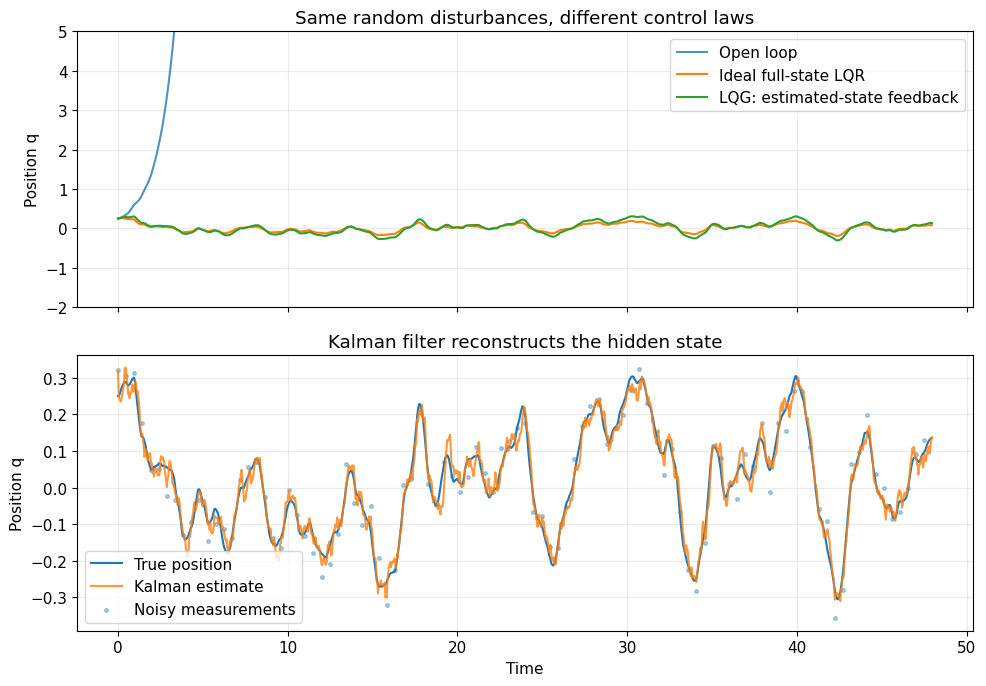

In [12]:
N=1200
rng=np.random.default_rng(2026)
W=rng.multivariate_normal([0,0],Qd,size=N)
V=rng.normal(0,np.sqrt(Rmeas),size=N)
K=lqr(A)
def simulate(mode):
    state=np.array([.25,0.]); state_hat=np.zeros(2); P=np.eye(2)*.2
    states=[];est=[];us=[];measure=[]
    for sample in range(N):
        measurement=(C@state)[0]+V[sample]
        # Measurement correction: Kalman estimate of [q,v].
        innovation=measurement-(C@state_hat)[0]
        S=(C@P@C.T)[0,0]+Rmeas
        L=(P@C.T/S).ravel()
        state_hat=state_hat+L*innovation
        T=np.eye(2)-np.outer(L,C.ravel())
        P=T@P@T.T+np.outer(L,L)*Rmeas
        u=0. if mode=='open' else float(-(K@(state if mode=='full' else state_hat))[0])
        states.append(state.copy());est.append(state_hat.copy());us.append(u);measure.append(measurement)
        state=Ad@state+Bd.ravel()*u+W[sample]
        state_hat=Ad@state_hat+Bd.ravel()*u
        P=Ad@P@Ad.T+Qd
    return np.array(states),np.array(est),np.array(us),np.array(measure)
open_state,_,_,_=simulate('open')
full_state,_,full_u,_=simulate('full')
lqg_state,lqg_est,lqg_u,lqg_measure=simulate('lqg')
time=np.arange(N)*dt
fig,axs=plt.subplots(2,1,figsize=(10,7),sharex=True)
axs[0].plot(time,open_state[:,0],label='Open loop',alpha=.8)
axs[0].plot(time,full_state[:,0],label='Ideal full-state LQR')
axs[0].plot(time,lqg_state[:,0],label='LQG: estimated-state feedback')
axs[0].set(ylim=(-2,5),ylabel='Position q',title='Same random disturbances, different control laws');axs[0].legend()
axs[1].plot(time,lqg_state[:,0],label='True position')
axs[1].plot(time,lqg_est[:,0],label='Kalman estimate',alpha=.8)
axs[1].scatter(time[::12],lqg_measure[::12],s=7,alpha=.35,label='Noisy measurements')
axs[1].set(xlabel='Time',ylabel='Position q',title='Kalman filter reconstructs the hidden state');axs[1].legend()
fig.tight_layout();plt.show()


## 8. Linear quadratic Gaussian (LQG) = LQR + Kalman filter

The **separation principle** says that, under standard linear-Gaussian assumptions, the estimator and optimal feedback gains can be designed separately:

$$
\boxed{u_k=-K_d\hat{\mathbf s}_{k|k}}.
$$

Our simulation above uses a continuous-time LQR gain applied to a sampled plant (adequate here at small $dt$). For the paper's FPGA, a **discrete-time LQR gain** is calculated directly. The following cell computes that discrete-time gain and compares it with our approximation. A discrete-time cost with $Q_d^{\mathrm{LQR}}\approx Q_{\mathrm{LQR}}dt$ and $R_d^{\mathrm{LQR}}\approx r\,dt$ is used here; these cost matrices are **distinct** from the stochastic process covariance $Q_d$ and measurement covariance $R_d$.


In [13]:
Pd=solve_discrete_are(Ad,Bd,Qcontrol*dt,rcontrol*dt)
Kd=np.linalg.solve(Bd.T@Pd@Bd+rcontrol*dt,Bd.T@Pd@Ad)
print('Continuous-time LQR gain:',K.round(4))
print('Discrete-time LQR gain:  ',Kd.round(4))
print('Discrete closed-loop eigenvalues:',np.linalg.eigvals(Ad-Bd@Kd).round(4))

Continuous-time LQR gain: [[3.2361 2.7932]]
Discrete-time LQR gain:   [[3.1146 2.6977]]
Discrete closed-loop eigenvalues: [0.9433+0.0128j 0.9433-0.0128j]


### Why did the authors choose LQG rather than another controller?

The short answer is that **LQG is a natural engineering choice for a noisy, approximately linear mechanical system whose full state cannot be measured**. However, LQG is **not the only way to stabilise an inverted trap**, and the paper does not claim a controlled comparison proving it is superior to alternatives.

Recall that **LQG = Kalman state estimator + LQR state-feedback law**. These solve two *different* problems:

1. **Estimate what we cannot measure reliably.** The detector mostly provides noisy displacement-related voltages, not direct measurements of all velocities. A Kalman filter combines detector information with the oscillator model to estimate position and velocity. Simply differentiating a noisy position measurement tends to magnify high-frequency noise. (A filtered derivative or another observer can also work.)
2. **Choose how strongly to react.** The LQR chooses feedback gains to minimise a *specified* quadratic cost, typically penalising displacement, velocity and excessive force. In a **stable** harmonic trap, positive state weights can be chosen proportional to mechanical energy. At the **inverted** equilibrium, physical potential energy has negative curvature, so the positive LQR position penalty is an *energy-inspired stabilisation objective*, not the true local mechanical energy.
3. **Make noise explicit.** The Kalman estimator uses process- and measurement-noise covariances. It is minimum-mean-square-error optimal for the *assumed linear Gaussian model*, not automatically for an inaccurate or nonlinear one.
4. **Run fast on an FPGA.** Estimator and feedback gains can be calculated before the experiment. The real-time loop consists mostly of fixed-size matrix-vector operations. In the paper the controller updates every **64 ns** (15.625 MHz), using fixed-point arithmetic.

In a single-axis inverted trap, ordinary position-and-velocity feedback already has the form

$$
u=-g_q\,q-g_v\,v.$$

Its stability conditions in our normalised model are $g_q>\Omega_0^2$ and $\Gamma+g_v>0$. **Those conditions do not require LQG.** LQR is one systematic method for choosing the two gains; the Kalman filter supplies estimated states when the true states are not directly available.

| Method | Why we might use it | What it does not automatically solve |
|:--|:--|:--|
| **Proportional–derivative (PD) / proportional–integral–derivative (PID)** | Simple, cheap, often sufficient for one well-measured axis | Derivative noise; tuning multiple coupled modes |
| **Pole placement + observer** | Direct control over local closed-loop poles; efficient FPGA implementation | The poles alone do not select the best noise/effort trade-off |
| **LQG (Kalman + LQR)** | Explicit measurement/process noise model and quadratic performance criterion; precomputed gains | Does not guarantee robustness to plant uncertainty, delay or actuator saturation |
| **$H_\infty$ (H-infinity) control** | Can explicitly design for bounded disturbances/model uncertainty | Requires more involved modelling and weighting choices |
| **Model predictive control (MPC)** | Can incorporate input limits and state constraints directly | Typically needs more online computation; careful fast implementation |
| **Nonlinear control** | Can use the full double-well dynamics beyond a local linearisation | Generally more complex to design and validate |

**Important distinction:** The LQG law is still *linear observer-based state feedback*. Its special property is the **choice of gains** (and the assumptions that justify those choices), not a new physical mechanism of trapping.


LQR gains:                       [3.23607 2.79317]
Pole-placement gains, same poles: [3.23607 2.79317]
Pole-placement gains, other poles: [1.85 1.08]
Maximum same-pole gain difference: 4.440892098500626e-16


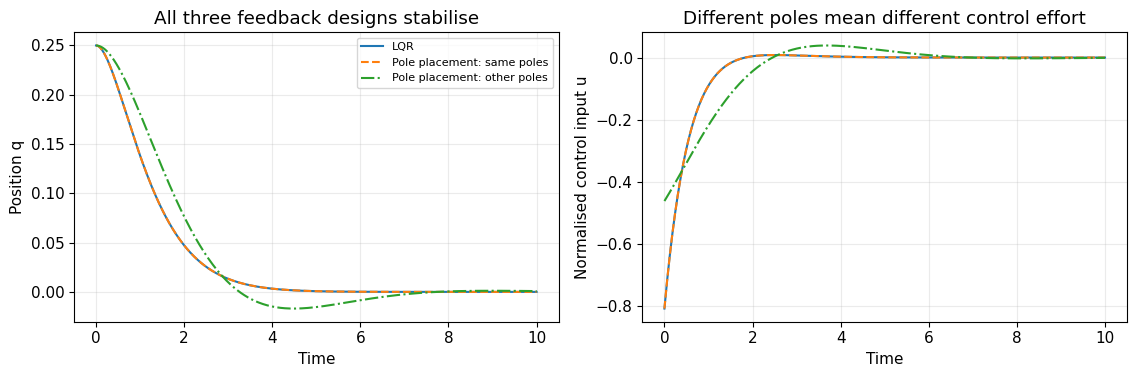

In [14]:
# Compare ordinary pole-placement feedback with the LQR from Sections 6-8.
# This is a deterministic illustration; it does NOT demonstrate that one
# controller is more robust or has lower noise-induced variance in practice.
from scipy.signal import place_poles

K_lqr_compare = lqr(plant(-1)).ravel()
A_compare = plant(-1)

# Choose the EXACT closed-loop poles obtained from LQR.
poles_lqr = np.linalg.eigvals(A_compare - B @ K_lqr_compare[None, :])
K_place_same = place_poles(A_compare, B, poles_lqr).gain_matrix.ravel()

# Choose some different but still stable poles for another valid PD controller.
other_poles = np.array([-0.6+0.7j, -0.6-0.7j])
K_place_other = place_poles(A_compare, B, other_poles).gain_matrix.ravel()

print('LQR gains:                      ', np.round(K_lqr_compare, 5))
print('Pole-placement gains, same poles:', np.round(K_place_same, 5))
print('Pole-placement gains, other poles:', np.round(K_place_other, 5))
print('Maximum same-pole gain difference:', np.max(abs(K_lqr_compare-K_place_same)))

# For a controllable two-state, one-input system, choosing the same poles
# uniquely fixes the state-feedback gain: it reproduces LQR exactly.
t_compare = np.linspace(0, 10, 500)
initial_state = np.array([0.25, 0.])
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
for gains, label, style in [
    (K_lqr_compare, 'LQR', '-'),
    (K_place_same, 'Pole placement: same poles', '--'),
    (K_place_other, 'Pole placement: other poles', '-.')
]:
    A_feedback = A_compare - B @ gains[None, :]
    trajectory = np.array([expm(A_feedback*t) @ initial_state for t in t_compare])
    applied_force = -(trajectory @ gains)
    axes[0].plot(t_compare, trajectory[:, 0], style, label=label)
    axes[1].plot(t_compare, applied_force, style, label=label)
axes[0].set(title='All three feedback designs stabilise', xlabel='Time', ylabel='Position q')
axes[1].set(title='Different poles mean different control effort', xlabel='Time', ylabel='Normalised control input u')
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()


**What does the comparison show?** In this *controllable, two-state, single-input* example, specifying exactly the LQR closed-loop poles via pole placement reproduces the LQR gains (and hence the same response). A different choice of stable poles also works, but gives different settling behaviour and feedback effort. This shows why **stabilisation alone does not establish that LQG is better than PD or pole placement**. For multiple-input systems, the same poles need not uniquely determine the feedback matrix.

### How strong is the evidence in the supplied paper?

Mlynář *et al.* demonstrate an FPGA implementation of the discrete-time Kalman filter and LQR, together with a **second FPGA acting as a nonlinear stochastic hardware-in-the-loop (HIL) particle simulator**. Their Section 4 and Figure 5 demonstrate reduced fluctuations in a confining potential, successful closed-loop confinement at an otherwise unstable saddle, and loss of central confinement when feedback is disabled. This is a convincing **implementation and stabilisation demonstration**. It does **not** establish:

- that LQG outperforms a comparably implemented PID, observer-based pole-placement, robust controller or MPC;
- that the same gain choice remains optimal far from the linearised equilibrium, especially when force saturates;
- that the experiment achieves quantum ground-state cooling (the reported end-to-end demonstration uses a HIL plant, not an actual trapped nanoparticle).

A useful *fair* comparison would keep the **same detector signals, Kalman estimator, actuator limits, sampling rate and disturbances**, replacing only the feedback gain selection (for example, LQR versus pole placement). Report position variance, control effort, settling time, sensitivity to uncertain trap stiffness or delay, and the **largest initial displacement that can be recovered**. The last metric is especially important for the double-well example in Section 10.

**Takeaway:** In this paper, LQG is attractive because it is **noise-aware, systematically designed and FPGA-friendly**. The unusual physics result is *stabilising an unstable trap*; LQG is a practical way to do so, not the only possible way.


## 9. Cooling and stabilisation are different control objectives

**Stable trap:** feedback can increase damping and reduce stationary motion in the presence of random forces. **Inverted trap:** without feedback, there is no stationary distribution about the central equilibrium; the first priority is to make the closed-loop dynamics stable.

For a stable linear system with white process noise, the steady-state state covariance $\Sigma$ satisfies the discrete Lyapunov equation

$$
\Sigma=A_{\mathrm{cl}}\Sigma A_{\mathrm{cl}}^T+Q_d.
$$

The mechanical energy in a *stable* harmonic trap (with normalised $m=1$) is $E=(v^2+\Omega^2q^2)/2$. Smaller stationary variance corresponds to less mechanical energy. Here we simulate open-loop and full-state velocity-feedback cooling; measurement-based LQG can add noise through imperfect estimates.


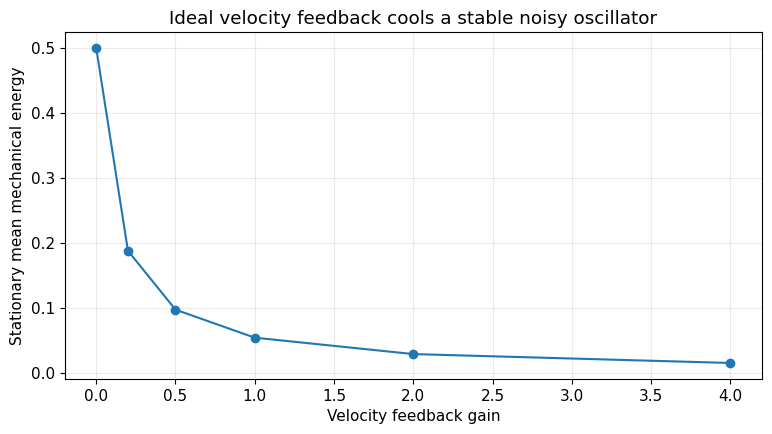

Energy without feedback: 0.5   with gain 2: 0.0289


In [15]:
from scipy.linalg import solve_discrete_lyapunov
Ast=plant(1)
Ads,Bds,_,_,_=cont2discrete((Ast,B,C,np.zeros((1,1))),dt)
M=np.block([[Ast,Q_process_ct],[np.zeros((2,2)),-Ast.T]])*dt
EM=expm(M);Qds=EM[:2,2:]@EM[:2,:2].T;Qds=(Qds+Qds.T)/2
energy=[]
for kv in [0,.2,.5,1.,2.,4.]:
    F=Ads-Bds@np.array([[0.,kv]])
    Sigma=solve_discrete_lyapunov(F,Qds)
    energy.append(.5*(Sigma[0,0]+Sigma[1,1]))
plt.plot([0,.2,.5,1.,2.,4.],energy,'o-');plt.xlabel('Velocity feedback gain');plt.ylabel('Stationary mean mechanical energy')
plt.title('Ideal velocity feedback cools a stable noisy oscillator');plt.show()
print('Energy without feedback:',round(energy[0],4),'  with gain 2:',round(energy[-2],4))

**Caveat:** The preceding graph assumes ideal full-state feedback, no actuator limits and no measurement noise. A practical LQG controller has an optimum gain; stronger feedback is not always better once measurement noise, bandwidth, delay and quantisation are included.

## 10. The paper's double-well / saddle example

The paper's illustrative two-dimensional potential is **separable**. To distinguish its mechanical mode coordinates from our optical beam axes $(x,y,z)$, we call them $q_1,q_2$:

$$
V_{\mathrm{con}}(q_1,q_2)=\tfrac12\Omega_1^2q_1^2+\tfrac12\Omega_2^2q_2^2,
$$
$$
V_{\mathrm{sad}}(q_1,q_2)=\tfrac14\alpha_1^4q_1^4-\tfrac12\Omega_1^2q_1^2+\tfrac12\Omega_2^2q_2^2.
$$

The symbol $\alpha_1$ below is the quartic-potential parameter used by the paper, **not** the dielectric polarizability $\alpha$ in Section 1. Here $V$ denotes a **normalised potential per unit mass**, so the quadratic coefficients have angular-frequency-squared units; the earlier $U$ denoted *physical optical potential energy*. At the origin, the saddle is unstable in $q_1$, stable in $q_2$. Away from the origin, the quartic term produces two wells in $q_1$. The paper uses a **linear** LQG controller near the operating point and a hardware-in-the-loop simulator of the **nonlinear** potential. Local feedback stability does not imply global performance throughout the double well.


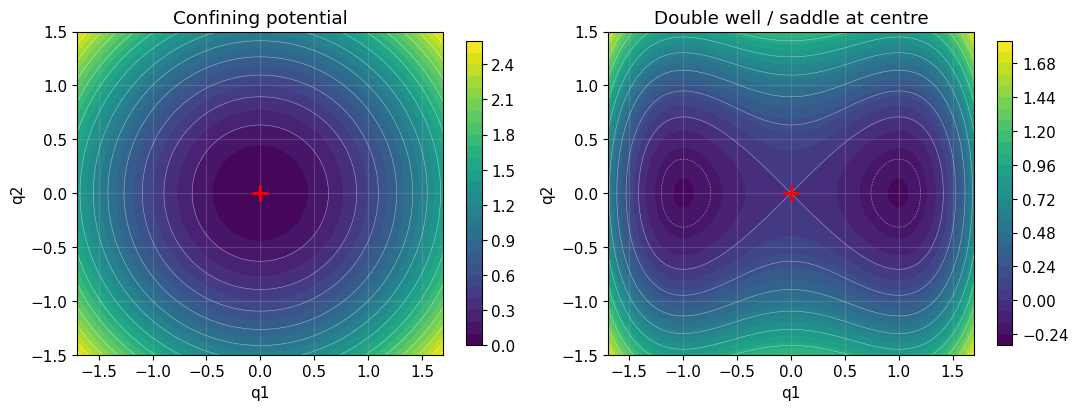

In [16]:
xx=np.linspace(-1.7,1.7,180);yy=np.linspace(-1.5,1.5,160)
X,Y=np.meshgrid(xx,yy)
Vcon=.5*(X**2+Y**2)
Vsad=.25*X**4-.5*X**2+.5*Y**2
fig,axs=plt.subplots(1,2,figsize=(11,4.3))
for a,Z,title in zip(axs,[Vcon,Vsad],['Confining potential','Double well / saddle at centre']):
    cs=a.contourf(X,Y,Z,levels=30,cmap='viridis');a.contour(X,Y,Z,levels=12,colors='white',linewidths=.4,alpha=.5)
    a.plot(0,0,'r+',ms=11,mew=2);a.set(xlabel='q1',ylabel='q2',title=title,aspect='equal');fig.colorbar(cs,ax=a,shrink=.8)
fig.tight_layout();plt.show()

### Nonlinear particle: why actuator limits matter

For one generic mechanical coordinate $q$, use the dimensionless double-well potential $V(q)=q^4/4-q^2/2$, so the normalised force-per-mass is $f(q)=q-q^3$. Without feedback, a particle displaced from the unstable centre tends towards one of the wells near $q=\pm 1$. We design **linear LQR** using the local approximation $\ddot q\approx q-\Gamma\dot q+u$.

There is a subtle point: **for this specific model, ideal *unlimited* feedback $u=-g_q\,q-g_v\,v$ actually stabilises the centre globally** when $g_q>1$ and $\Gamma+g_v>0$. The quartic restoring term helps at large displacements. So increasing starting displacement alone does *not* demonstrate failure of ideal feedback.

Real actuators have bounded force. To illustrate a genuine limitation, impose saturation $|u|\le u_{\max}$:

$$
u=\operatorname{clip}(-g_q\,q-g_v\,v,\,-u_{\max},\,u_{\max}).
$$

The next plots compare small and large initial displacements. For the larger displacement, the limited actuator cannot return the particle to the unstable centre, although unlimited feedback can. This is a simplified classical illustration, **not** a reproduction of the paper's Fig. 5.


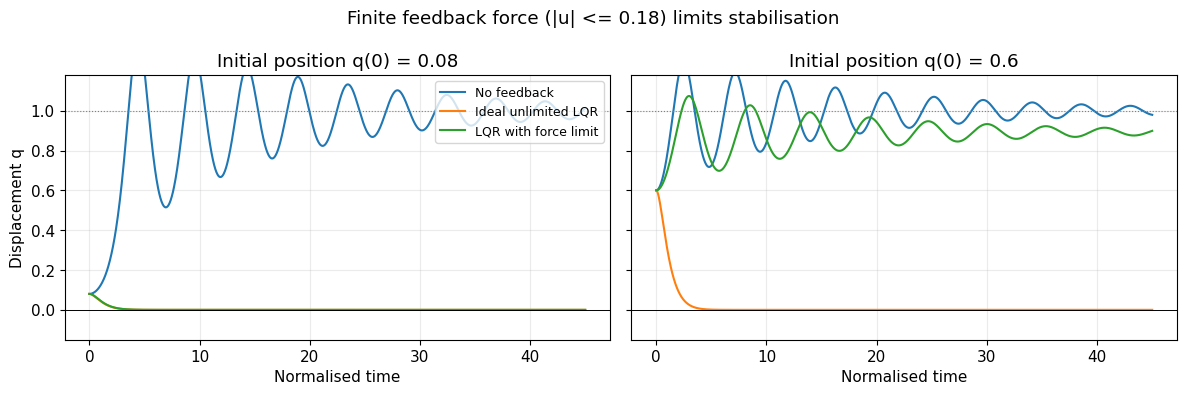

Limited feedback, q(0)=0.08: final q=0.000
Limited feedback, q(0)=0.60: final q=0.894


In [17]:
# The LQR gain K was calculated from the linearised inverted trap in Section 7.
u_max = 0.18  # maximum magnitude of normalised feedback acceleration

def nonlinear_saddle(time, state, mode='none'):
    q, v = state
    u_ideal = -float(K.ravel() @ state)
    if mode == 'ideal':
        u = u_ideal
    elif mode == 'limited':
        u = np.clip(u_ideal, -u_max, u_max)
    else:
        u = 0.0
    return [v, q - q**3 - gamma*v + u]

# Run from a small displacement and a larger displacement, both at rest.
tp = np.linspace(0, 45, 1300)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, q_initial in zip(axes, [0.08, 0.60]):
    for mode, label in [('none', 'No feedback'),
                        ('ideal', 'Ideal unlimited LQR'),
                        ('limited', 'LQR with force limit')]:
        sol = solve_ivp(lambda t, st: nonlinear_saddle(t, st, mode),
                        [tp[0], tp[-1]], [q_initial, 0.0], t_eval=tp,
                        rtol=1e-8, atol=1e-10)
        ax.plot(sol.t, sol.y[0], label=label)
    ax.axhline(0, color='black', lw=.7)
    ax.axhline(1, color='grey', ls=':', lw=.8)
    ax.set(title=f'Initial position q(0) = {q_initial}',
           xlabel='Normalised time', ylim=(-.15, 1.18))
axes[0].set_ylabel('Displacement q')
axes[0].legend(loc='upper right', fontsize=9)
fig.suptitle(f'Finite feedback force (|u| <= {u_max}) limits stabilisation')
fig.tight_layout()
plt.show()

for q_initial in [0.08, 0.60]:
    sol = solve_ivp(lambda t, st: nonlinear_saddle(t, st, 'limited'),
                    [0, 100], [q_initial, 0.0], rtol=1e-8, atol=1e-10)
    print(f'Limited feedback, q(0)={q_initial:.2f}: final q={sol.y[0,-1]:.3f}')


## 11. What does the FPGA add?

The **control theory** is standard; the engineering challenge is to run it deterministically with low latency and controlled numerical error.

In the supplied paper:

- The FPGA controller uses a **64 ns sample period** (15.625 MHz) and fixed-point matrix operations.
- It supports **up to three oscillatory degrees of freedom plus a drift state**, with two analogue inputs and two outputs.
- The authors describe state-space rescaling to reduce fixed-point quantisation problems.
- A second Red Pitaya FPGA implements a stochastic nonlinear **hardware-in-the-loop (HIL) plant**, including lookup-table nonlinearities and noise generators.
- Their end-to-end example demonstrates a transition from a confining potential to a saddle potential and back, including loss of confinement when feedback is disabled.

The demonstration is **HIL, not a new measurement of quantum ground-state cooling**. In the real experiment, the simulated plant would be replaced by an optically trapped particle and the voltages would drive a physical actuator.

### Why latency matters

If feedback is delayed, a force intended to oppose velocity may arrive at the wrong phase of the oscillation. The next figure shows the phase-lag magnitude $|\varphi|=\Omega\tau$ (the signed phase is $-\Omega\tau$) for several delays, as a simple first-order illustration. A full stability assessment must include the sampled controller and actuator dynamics.

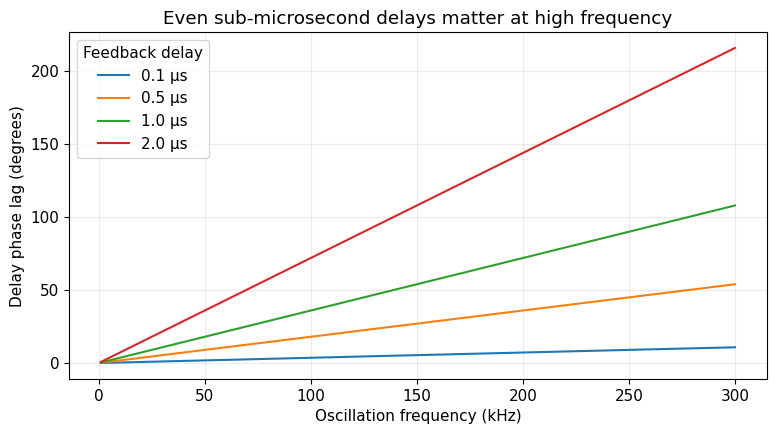

In [18]:
freq=np.linspace(1e3,300e3,400)
for delay_us in [.1,.5,1.,2.]:
    plt.plot(freq/1e3,360*freq*delay_us*1e-6,label=f'{delay_us} µs')
plt.xlabel('Oscillation frequency (kHz)');plt.ylabel('Delay phase lag (degrees)');plt.title('Even sub-microsecond delays matter at high frequency');plt.legend(title='Feedback delay');plt.show()

## 12. Putting it all together

1. **Optical field:** a beam travelling along $+x$ has transverse restoring gradients in $y,z$; an axial gradient can balance forward scattering near its focus. The controlled coordinate $q$ is distinct from the optical axial position $x$.
2. **Mechanical plant:** a generic controlled mode $q$ follows a noisy second-order equation of motion, with state $\mathbf s=[q,v]^T$.
3. **Stable trap:** optical restoring forces already confine the particle; feedback can cool its motion.
4. **Saddle trap:** the desired equilibrium is unstable without feedback; active position feedback must first supply effective positive stiffness.
5. **Kalman filter:** estimates position and velocity from noisy detector outputs.
6. **LQR:** chooses feedback gains that trade state excursions against actuation effort.
7. **LQG:** combines those two components; it is an effective, not unique, route to stabilisation. Its gain selection is systematic but remains model-dependent. The FPGA makes the loop fast and deterministic.
8. **HIL:** replaces the physical particle with a nonlinear stochastic real-time simulator to test the controller safely.

### Exercises (change code and rerun)

- Increase `Rmeas` tenfold in §7. Does the Kalman estimate become less reliable? How does the LQG trajectory change?
- Increase `rcontrol` in §6. Why does the controller become less aggressive?
- Change `gamma` in §4 and re-run the simulation. What happens to the open-loop unstable pole?
- In §10, change `u_max` and the initial displacement in the nonlinear double-well example. When does **limited-force feedback** stop holding the particle near the unstable centre? Compare with unlimited feedback.
- Replace the continuous-time LQR gain in §7 with the discrete-time `Kd` computed in §8. Compare the results.
- In the controller-comparison cell after §8, change `other_poles`. How do the position response and feedback force change? What additional test would be needed to compare noise rejection fairly?

### Further reading

- Mlynář et al. (2026), *FPGA-based LQG controller and hardware-in-the-loop simulator implementation for nanomechanical systems*, supplied PDF, especially §§2 and 4.
- Winstone et al. (2023), *Optomechanics of optically-levitated particles: A tutorial and perspective*, arXiv:2307.11858.
- Millen et al. (2020), *Optomechanics with levitated particles*, *Reports on Progress in Physics* 83, 026401.

**Limitations of this notebook:** classical linear-Gaussian noise; simplified 1D dynamics for control; illustrative normalised values; no photon-recoil quantum backaction, detailed actuator dynamics beyond a simple saturation limit, explicit fixed-point FPGA model, or detailed optical scattering calculation. These would be natural follow-on topics.